# Socioeconomic and Racial Factors Influencing Larceny Rates in U.S. Regions

This notebook contains the full analysis behind the paper in [`paper/`](../paper/). It explores how
income, poverty, employment and racial composition relate to larceny rates in U.S. communities, and
compares how well several machine learning models predict larceny rates in each region.

**Data:** [Communities and Crime Unnormalized](https://archive.ics.uci.edu/dataset/211/communities+and+crime+unnormalized)
(UCI Machine Learning Repository), which combines 1990 U.S. Census data, 1990 LEMAS police data and
1995 FBI Uniform Crime Reports for 2,215 communities.

**Contents**
1. Setup
2. Load and prepare the data
3. Exploratory analysis
4. Regional models: Baseline, CART, Random Forest and Gradient Boosting
5. Model comparison: Logistic Regression, Linear Regression and Random Forest
6. K-Means clustering

Figure and table numbers match the paper, so Figures 10 and 11 (section 5) appear before
Figures 7 to 9 (section 6). The crime type chart (`fig00`) isn't in the paper.

## 1. Setup

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_samples, silhouette_score)
from sklearn.model_selection import RandomizedSearchCV, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import make_pipeline

DATA_DIR = Path("../data")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

pd.options.display.float_format = "{:.3f}".format

In [2]:
# The nine predictor features used throughout the models
FEATURES = ["population", "medIncome", "NumUnderPov", "racepctblack", "racePctWhite",
            "racePctAsian", "racePctHisp", "PctUnemployed", "PctEmploy"]

# Five U.S. regions used for the regional comparison
REGIONS = {
    "Northeast": ["ME", "NH", "VT", "MA", "RI", "CT", "NY", "NJ", "PA"],
    "Southeast": ["DE", "MD", "VA", "WV", "KY", "TN", "NC", "SC", "GA", "FL", "AL", "MS", "AR", "LA", "DC"],
    "Midwest": ["OH", "MI", "IN", "IL", "WI", "MO", "IA", "MN", "ND", "SD", "NE", "KS"],
    "Southwest": ["TX", "OK", "NM", "AZ"],
    "West": ["CO", "WY", "MT", "ID", "UT", "NV", "CA", "OR", "WA", "AK", "HI"],
}
STATE_TO_REGION = {state: region for region, states in REGIONS.items() for state in states}

## 2. Load and prepare the data

`data/crimedata.csv` is created by `scripts/make_dataset.py`. Missing values appear as `?` in the
raw data.

In [3]:
df_raw = pd.read_csv(DATA_DIR / "crimedata.csv", encoding="latin1")
print(df_raw.shape)
df_raw.head()

(2215, 147)


,communityname,state,countyCode,communityCode,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,burglaries,burglPerPop,larcenies,larcPerPop,autoTheft,autoTheftPerPop,arsons,arsonsPerPop,ViolentCrimesPerPop,nonViolPerPop
0,BerkeleyHeightstownship,NJ,39,5320,1,11980,3.100,1.370,91.780,6.500,...,14,114.85,138,1132.08,16,131.26,2,16.41,41.02,1394.59
1,Marpletownship,PA,45,47616,1,23123,2.820,0.800,95.570,3.440,...,57,242.37,376,1598.78,26,110.55,1,4.25,127.56,1955.95
2,Tigardcity,OR,?,?,1,29344,2.430,0.740,94.330,3.430,...,274,758.14,1797,4972.19,136,376.3,22,60.87,218.59,6167.51
3,Gloversvillecity,NY,35,29443,1,16656,2.400,1.700,97.350,0.500,...,225,1301.78,716,4142.56,47,271.93,?,?,306.64,?
4,Bemidjicity,MN,7,5068,1,11245,2.760,0.530,89.160,1.170,...,91,728.93,1060,8490.87,91,728.93,5,40.05,?,9988.79


Keep only the identifiers, the predictor features and the target variable, `larcPerPop`
(larcenies per 100,000 population). Each community is then assigned to a region based on its state.

In [4]:
df1 = df_raw[["communityname", "state"] + FEATURES + ["larcenies", "larcPerPop"]].copy()
df1["region"] = df1["state"].map(STATE_TO_REGION).fillna("")

# larcPerPop contains "?" for missing values; convert it to numbers and drop the missing rows
df1["larcPerPop"] = pd.to_numeric(df1["larcPerPop"], errors="coerce")
df1 = df1.dropna(subset=["larcPerPop"]).reset_index(drop=True)

print(f"Rows: {df1.shape[0]}, columns: {df1.shape[1]}")
print(f"Duplicate rows: {df1.duplicated().sum()}")
df1.head()

Rows: 2212, columns: 14
Duplicate rows: 0


,communityname,state,population,medIncome,NumUnderPov,racepctblack,racePctWhite,racePctAsian,racePctHisp,PctUnemployed,PctEmploy,larcenies,larcPerPop,region
0,BerkeleyHeightstownship,NJ,11980,75122,227,1.370,91.780,6.500,1.880,2.700,64.550,138,1132.080,Northeast
1,Marpletownship,PA,23123,47917,885,0.800,95.570,3.440,0.850,2.430,61.960,376,1598.780,Northeast
2,Tigardcity,OR,29344,35669,1389,0.740,94.330,3.430,2.350,4.010,69.800,1797,4972.190,West
3,Gloversvillecity,NY,16656,20580,2831,1.700,97.350,0.500,0.700,9.860,54.740,716,4142.560,Northeast
4,Bemidjicity,MN,11245,17390,2855,0.530,89.160,1.170,0.520,9.080,52.440,1060,8490.870,Midwest


## 3. Exploratory analysis

### How common is larceny compared with other crimes?

Larcenies make up 52.89% of all reported crimes in the dataset.


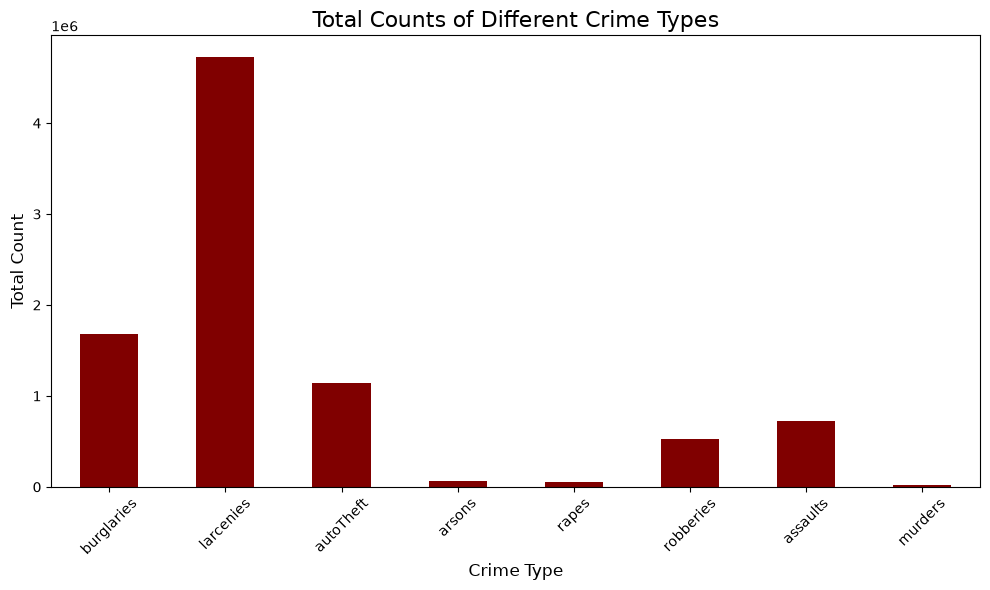

In [5]:
crime_cols = ["burglaries", "larcenies", "autoTheft", "arsons", "rapes", "robberies", "assaults", "murders"]
crime_totals = df_raw[crime_cols].apply(pd.to_numeric, errors="coerce").sum()

larceny_share = crime_totals["larcenies"] / crime_totals.sum() * 100
print(f"Larcenies make up {larceny_share:.2f}% of all reported crimes in the dataset.")

plt.figure(figsize=(10, 6))
crime_totals.plot(kind="bar", color="maroon")
plt.title("Total Counts of Different Crime Types", fontsize=16)
plt.xlabel("Crime Type", fontsize=12)
plt.ylabel("Total Count", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig00_crime_type_totals.png", dpi=150)
plt.show()

### Figure 1: Distribution of larcPerPop

Outliers (|z-score| > 3) are removed before plotting, then larceny rates are split into eight bins.

Removed 20 outliers.


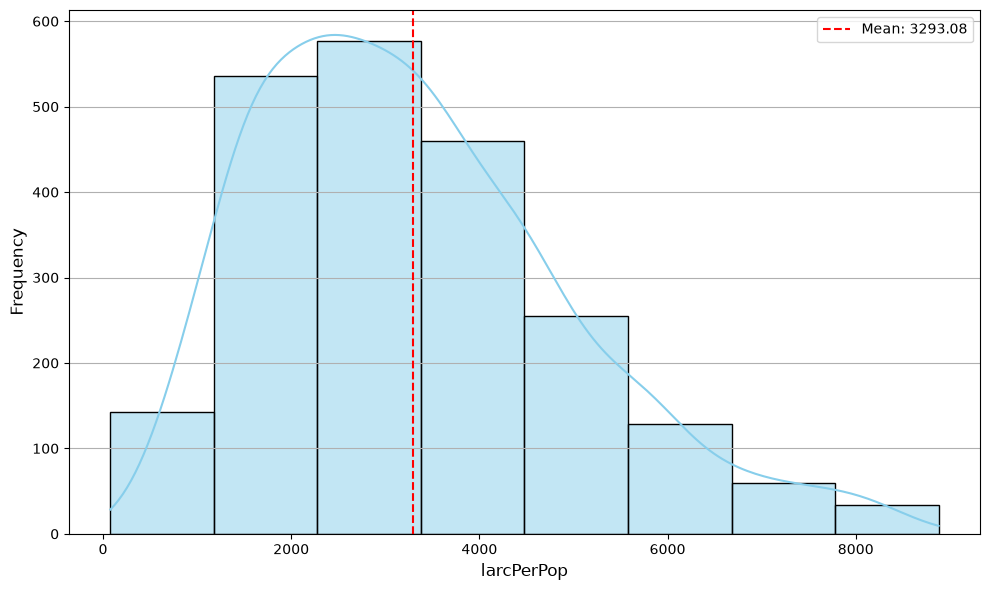

larcBinned
Low Moderate     577
Low              536
Moderate         460
High Moderate    255
Very Low         143
High             128
Very High         59
Severe            34
Name: count, dtype: int64

In [6]:
z_scores = (df1["larcPerPop"] - df1["larcPerPop"].mean()) / df1["larcPerPop"].std()
df2 = df1[z_scores.abs() <= 3].copy()
print(f"Removed {len(df1) - len(df2)} outliers.")

mean = df2["larcPerPop"].mean()
plt.figure(figsize=(10, 6))
sns.histplot(df2["larcPerPop"], bins=8, kde=True, color="skyblue", edgecolor="black")
plt.axvline(mean, color="red", linestyle="--", label=f"Mean: {mean:.2f}")
plt.xlabel("larcPerPop", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig01_larcperpop_distribution.png", dpi=150)
plt.show()

labels = ["Very Low", "Low", "Low Moderate", "Moderate", "High Moderate", "High", "Very High", "Severe"]
df2["larcBinned"] = pd.cut(df2["larcPerPop"], bins=8, labels=labels, right=False)
df2["larcBinned"].value_counts()

### Figure 2: United States separated by region

Uses the Census Bureau's 2018 state boundary file (`data/cb_2018_us_state_500k.zip`). Alaska and
Hawaii are moved and resized so they fit below the continental U.S.

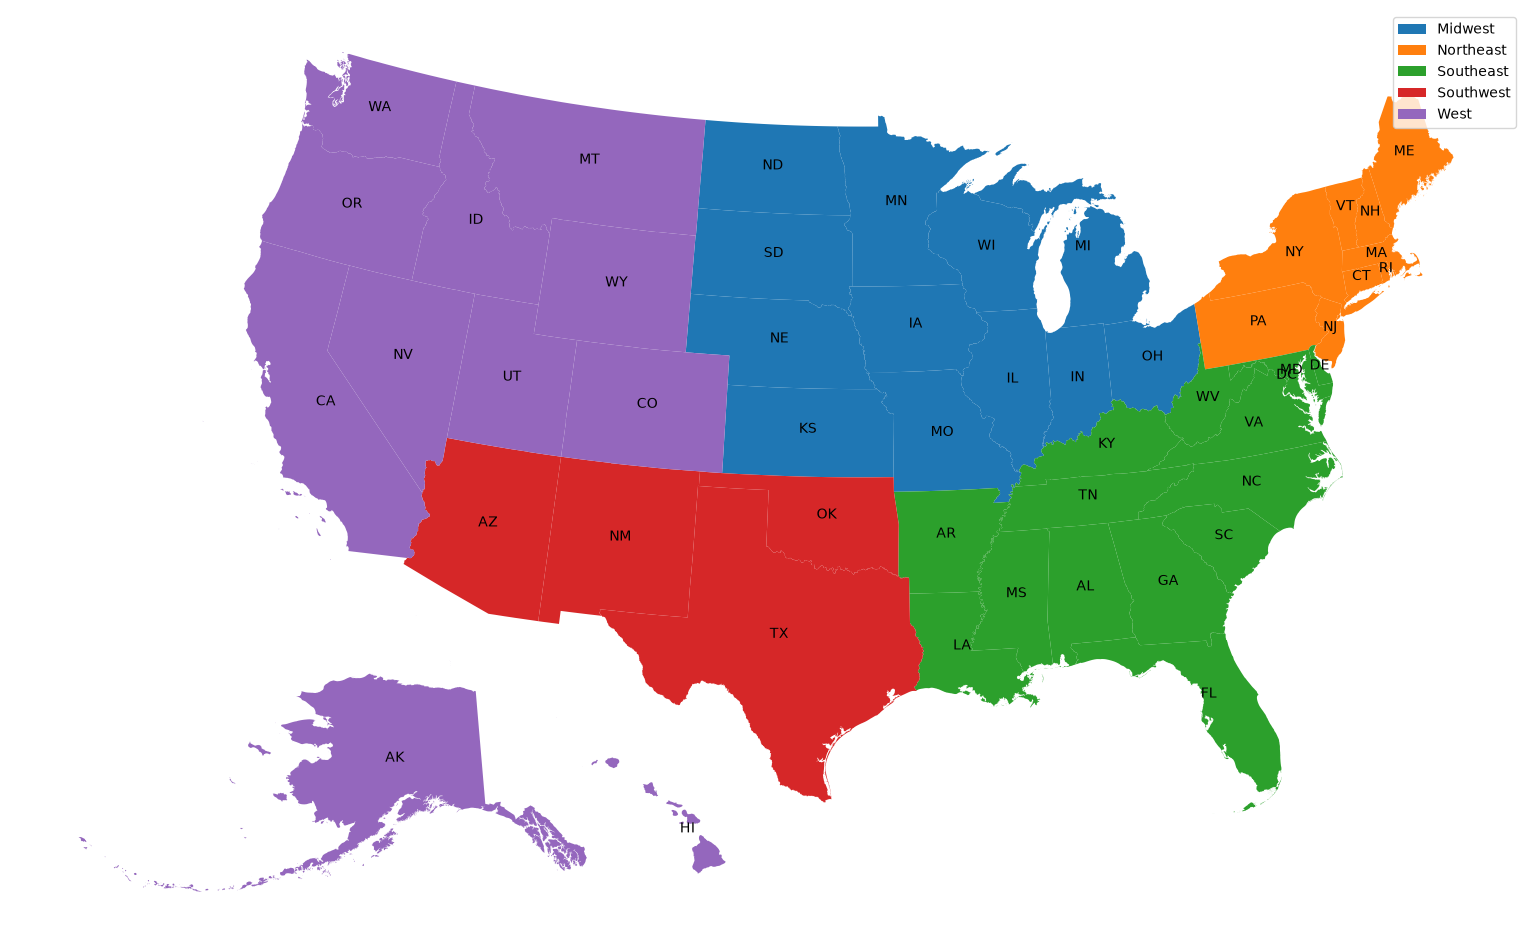

In [7]:
def translate_geometries(gdf, x, y, scale, rotate):
    gdf = gdf.copy()
    gdf["geometry"] = gdf.geometry.translate(xoff=x, yoff=y)
    center = gdf.dissolve().centroid.iloc[0]
    gdf["geometry"] = gdf.geometry.scale(xfact=scale, yfact=scale, origin=center)
    gdf["geometry"] = gdf.geometry.rotate(rotate, origin=center)
    return gdf


def adjust_maps(gdf):
    mainland = gdf[~gdf.STATEFP.isin(["02", "15"])]
    alaska = translate_geometries(gdf[gdf.STATEFP == "02"], 1300000, -4900000, 0.5, 32)
    hawaii = translate_geometries(gdf[gdf.STATEFP == "15"], 5400000, -1500000, 1, 24)
    return pd.concat([mainland, alaska, hawaii])


states = gpd.read_file(DATA_DIR / "cb_2018_us_state_500k.zip")
states = states[~states.STATEFP.isin(["72", "69", "60", "66", "78"])]  # drop U.S. territories
states = adjust_maps(states.to_crs("ESRI:102003"))
states["region"] = states["STUSPS"].map(STATE_TO_REGION)

fig, ax = plt.subplots(figsize=(20, 12))
states.plot(column="region", cmap="tab10", legend=True, ax=ax)
for _, row in states.iterrows():
    x, y = row["geometry"].centroid.coords[0]
    ax.text(x, y, row["STUSPS"], fontsize=10, ha="center", color="black")
ax.axis("off")
plt.savefig(FIG_DIR / "fig02_us_regions_map.png", dpi=150, transparent=True)
plt.show()

### Figure 3: Correlation heatmap of larceny and potential factors

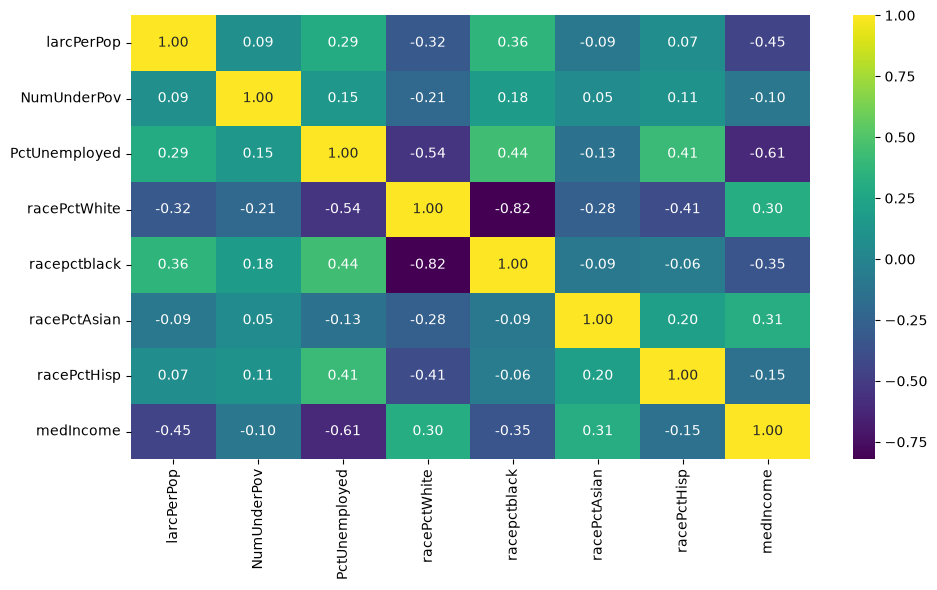

In [8]:
heatmap_vars = ["larcPerPop", "NumUnderPov", "PctUnemployed", "racePctWhite", "racepctblack",
                "racePctAsian", "racePctHisp", "medIncome"]

plt.figure(figsize=(10, 6))
sns.heatmap(df1[heatmap_vars].corr(), cmap="viridis", annot=True, fmt=".2f")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig03_correlation_heatmap.png", dpi=150)
plt.show()

### Figures 4 and 5: Larcenies per capita vs. unemployment and median income

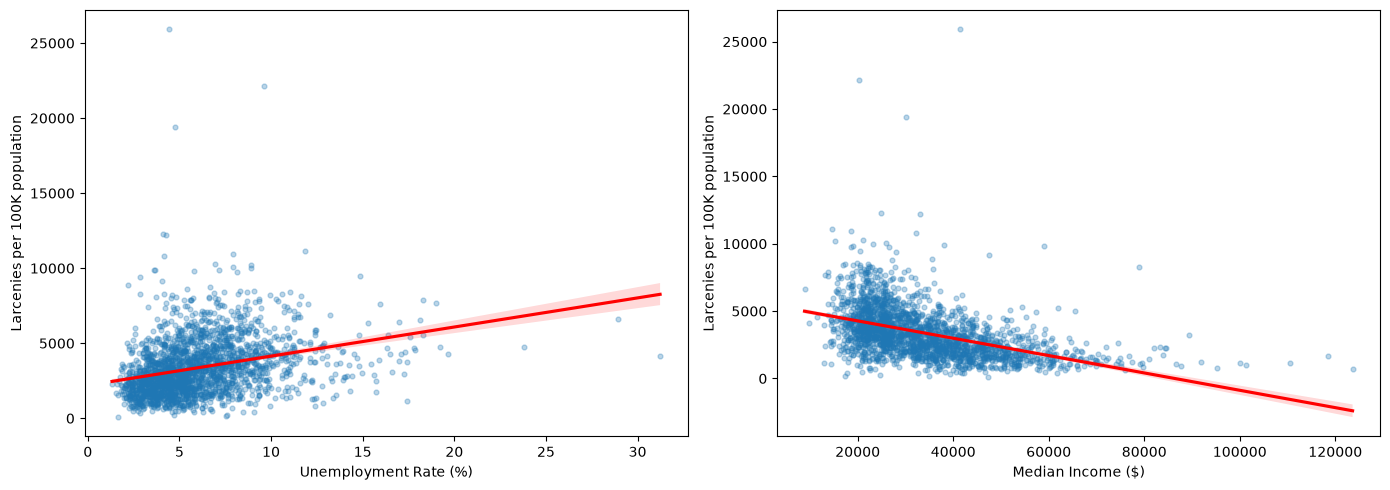

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, feature, title in zip(axes, ["PctUnemployed", "medIncome"],
                              ["Unemployment Rate (%)", "Median Income ($)"]):
    sns.regplot(data=df1, x=feature, y="larcPerPop", ax=ax,
                scatter_kws={"alpha": 0.3, "s": 12}, line_kws={"color": "red"})
    ax.set_xlabel(title)
    ax.set_ylabel("Larcenies per 100K population")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig04_05_larceny_vs_unemployment_income.png", dpi=150)
plt.show()

### Feature distributions

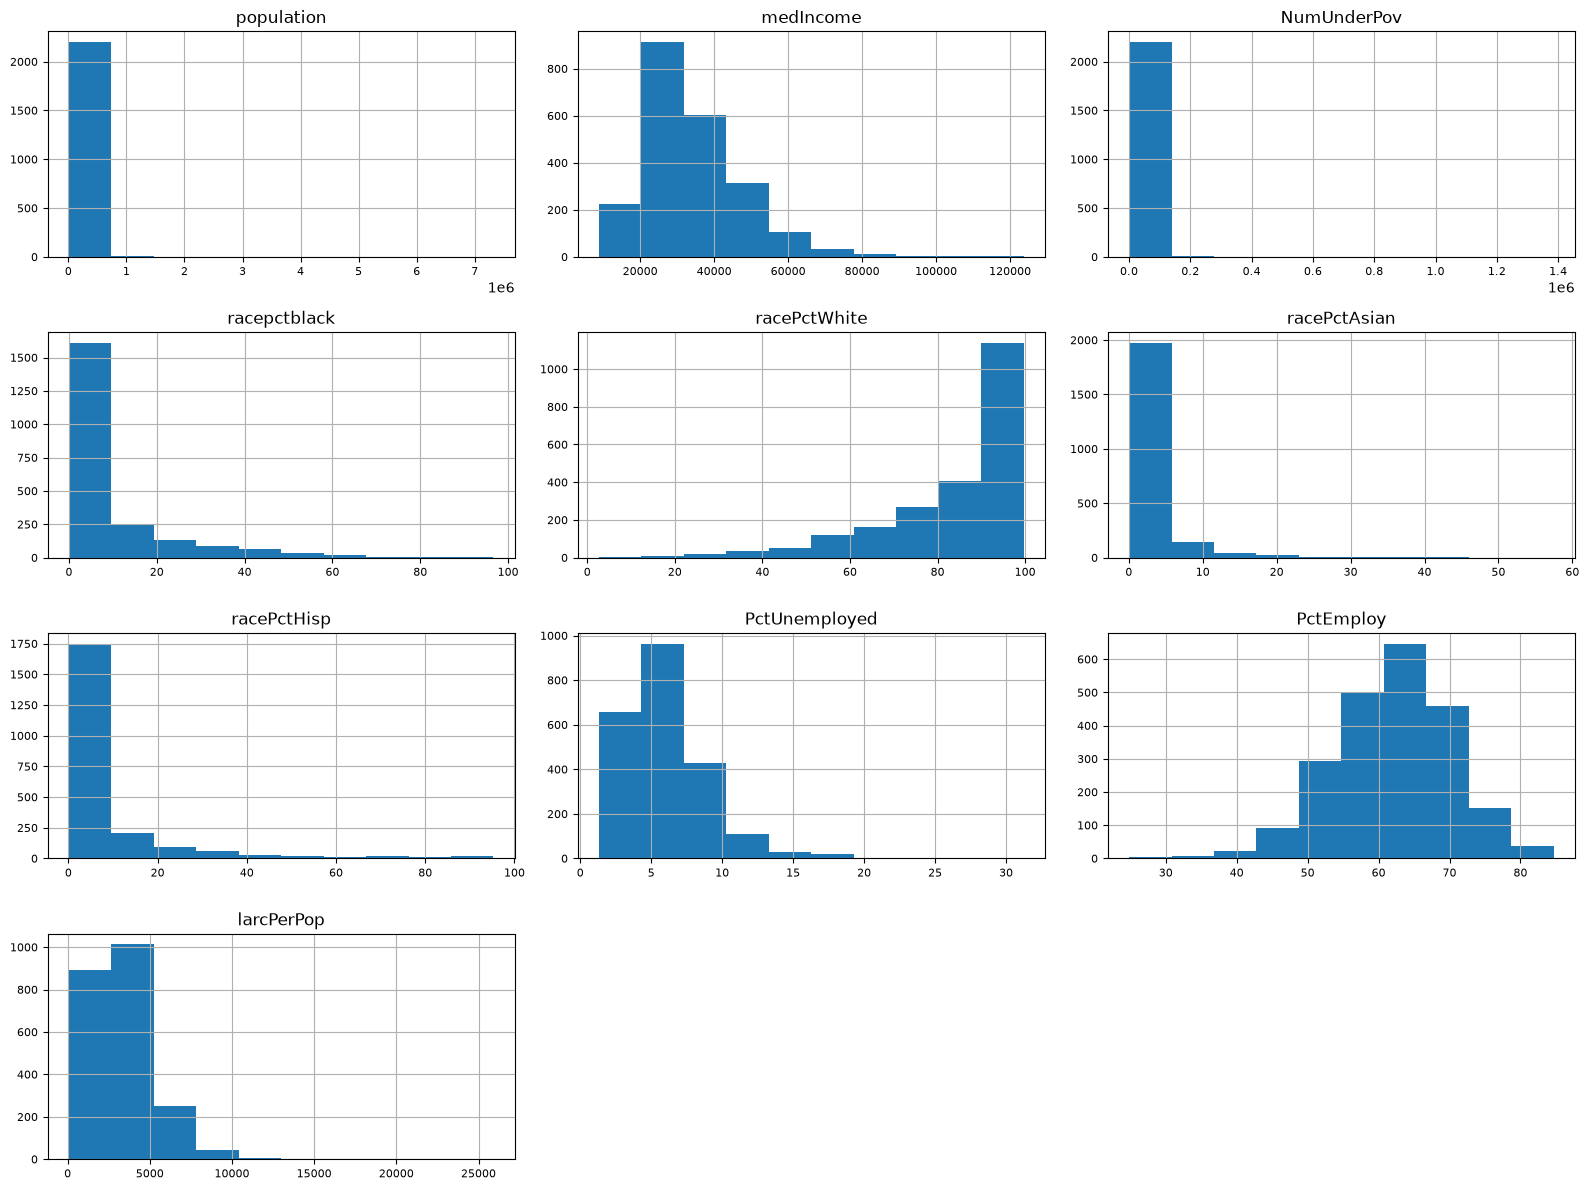

In [10]:
df1.select_dtypes(include="number").hist(figsize=(16, 12), xlabelsize=8, ylabelsize=8)
plt.tight_layout()
plt.show()

### Average larceny rate by region

In [11]:
df1.groupby("region")["larcPerPop"].mean().sort_values(ascending=False)

region
Southeast   4543.005
Southwest   3814.135
West        3499.974
Midwest     3291.158
Northeast   2374.897
Name: larcPerPop, dtype: float64

The Southeast has the highest average larceny rate and the Northeast has the lowest.

## 4. Regional models: Baseline, CART, Random Forest and Gradient Boosting

### Table 2: Baseline, CART and Random Forest on the full dataset

The baseline model predicts the mean larceny rate for every community. It gives a reference point for
judging the other models.

In [12]:
def eval_model(model_type, y_train, y_test, train_pred, test_pred):
    """Return MSE, MAE and R² on the training and testing sets as a one-row DataFrame."""
    return pd.DataFrame([{
        "Model Type": model_type,
        "Training MSE": mean_squared_error(y_train, train_pred),
        "Testing MSE": mean_squared_error(y_test, test_pred),
        "Training MAE": mean_absolute_error(y_train, train_pred),
        "Testing MAE": mean_absolute_error(y_test, test_pred),
        "Training R²": r2_score(y_train, train_pred),
        "Testing R²": r2_score(y_test, test_pred),
    }])

In [13]:
X = df1[FEATURES]
y = df1["larcPerPop"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=99)

baseline_pred = [y.mean()] * len(y)
baseline_df = eval_model("Baseline", y, y, baseline_pred, baseline_pred)

cart = DecisionTreeRegressor(random_state=99, max_depth=5).fit(X_train, y_train)
cart_df = eval_model("CART", y_train, y_test, cart.predict(X_train), cart.predict(X_test))

rf_overall = RandomForestRegressor(random_state=99, max_depth=5).fit(X_train, y_train)
rf_overall_df = eval_model("Random Forest", y_train, y_test,
                           rf_overall.predict(X_train), rf_overall.predict(X_test))

pd.concat([baseline_df, cart_df, rf_overall_df], ignore_index=True)

,Model Type,Training MSE,Testing MSE,Training MAE,Testing MAE,Training R²,Testing R²
0,Baseline,3613368.814,3613368.814,1404.123,1404.123,0.000,0.000
1,CART,1877800.513,2215277.717,994.208,1090.922,0.500,0.276
2,Random Forest,1778526.995,2150143.336,965.270,1060.258,0.526,0.297


### Figure 6: Model performance by region

A CART, Random Forest and Gradient Boosted model is trained separately for each region. Each model's
`max_depth` is tuned with cross-validation.

The baseline uses the national mean and is scored on the whole dataset, so its MSE and MAE aren't
directly comparable with each region's test set. R² is the fairest comparison in this figure.

In [14]:
def calc_depth(X_train, y_train, model, max_depth_range=range(1, 11)):
    """Find the best max_depth for a model using cross-validated search."""
    search = RandomizedSearchCV(estimator=model, param_distributions={"max_depth": max_depth_range},
                                n_iter=len(max_depth_range), cv=3, scoring="r2", random_state=99)
    search.fit(X_train, y_train)
    return search.best_params_["max_depth"]


def create_models(region_df):
    """Train and evaluate CART, Random Forest and Gradient Boosted models for one region."""
    region = region_df["region"].iloc[0]
    X_train, X_test, y_train, y_test = train_test_split(
        region_df[FEATURES], region_df["larcPerPop"], test_size=0.2, random_state=99)

    models = {
        "CART": DecisionTreeRegressor(random_state=99),
        "Random Forest": RandomForestRegressor(random_state=99, n_estimators=100),
        "Gradient Boosted": GradientBoostingRegressor(random_state=99, n_estimators=100, learning_rate=0.1),
    }
    results = []
    for name, model in models.items():
        model.set_params(max_depth=calc_depth(X_train, y_train, model))
        model.fit(X_train, y_train)
        results.append(eval_model(f"{name} ({region})", y_train, y_test,
                                  model.predict(X_train), model.predict(X_test)))
    return pd.concat(results)

In [15]:
region_results = [create_models(df1[df1["region"] == region].reset_index(drop=True))
                  for region in REGIONS]
results_df = (pd.concat([baseline_df] + region_results, ignore_index=True)
              .sort_values(by="Model Type"))
results_df

,Model Type,Training MSE,Testing MSE,Training MAE,Testing MAE,Training R²,Testing R²
0,Baseline,3613368.814,3613368.814,1404.123,1404.123,0.000,0.000
7,CART (Midwest),1648723.012,1190144.838,927.408,831.871,0.254,0.235
1,CART (Northeast),3165320.199,1280254.143,952.480,899.644,0.102,0.061
4,CART (Southeast),2774941.698,3744408.559,1285.367,1500.108,0.299,0.135
10,CART (Southwest),1295544.199,2042685.037,837.973,1027.466,0.496,0.239
13,CART (West),2759360.404,2802383.273,1140.273,1307.314,0.181,0.139
9,Gradient Boosted (Midwest),1450857.462,1162605.555,873.315,821.219,0.344,0.253
3,Gradient Boosted (Northeast),2532058.490,1174708.227,831.518,883.015,0.281,0.138
6,Gradient Boosted (Southeast),2232340.883,3115438.789,1170.819,1316.074,0.436,0.281
12,Gradient Boosted (Southwest),992733.590,2255739.608,727.088,1088.714,0.614,0.160


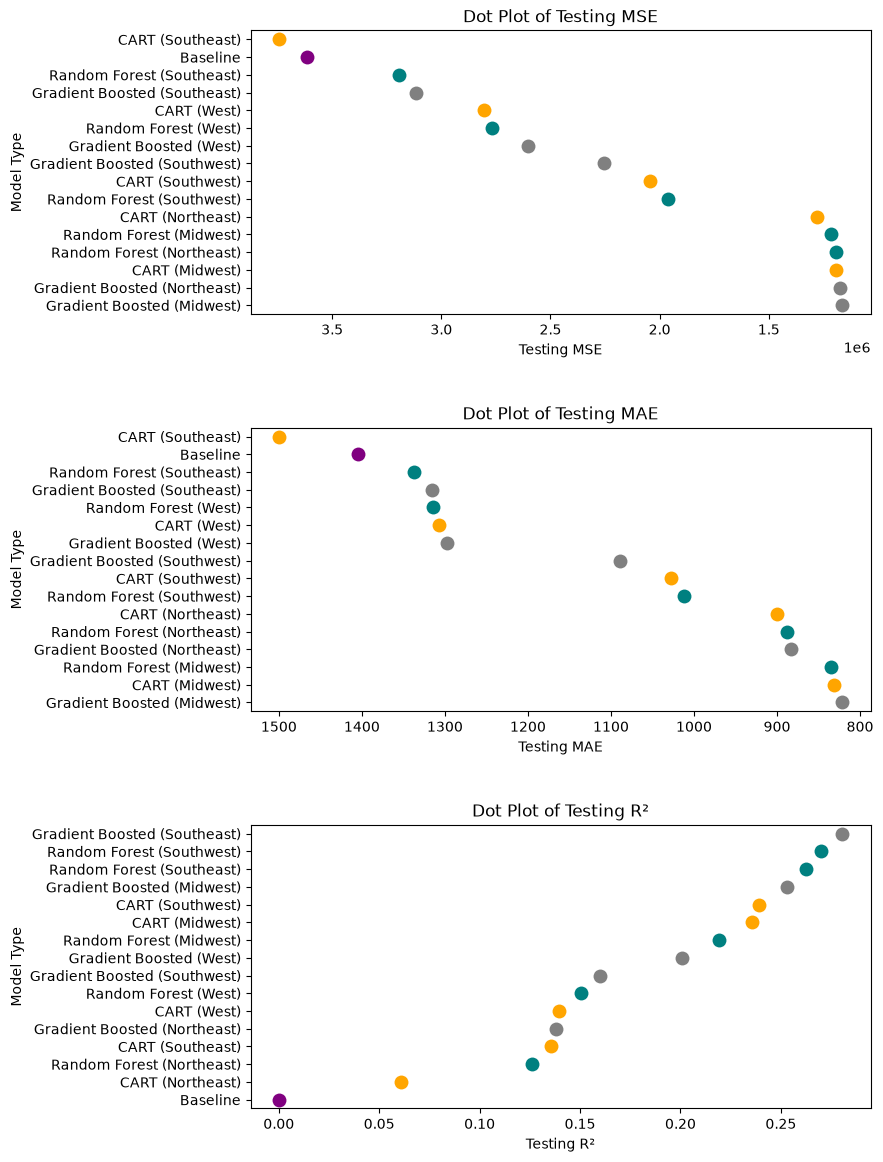

In [16]:
MODEL_COLORS = {"Baseline": "purple", "CART": "orange", "Random Forest": "teal", "Gradient Boosted": "gray"}
palette = {m: next(c for k, c in MODEL_COLORS.items() if k in m) for m in results_df["Model Type"]}

fig, axes = plt.subplots(3, 1, figsize=(8, 14))
plt.subplots_adjust(hspace=0.4)
for ax, metric, lower_is_better in zip(axes, ["Testing MSE", "Testing MAE", "Testing R²"], [True, True, False]):
    data = results_df.sort_values(by=metric, ascending=False)
    sns.stripplot(x=metric, y="Model Type", data=data, ax=ax, size=10,
                  hue="Model Type", palette=palette, legend=False)
    ax.set_title(f"Dot Plot of {metric}")
    if lower_is_better:
        ax.invert_xaxis()  # so that further right always means better
plt.savefig(FIG_DIR / "fig06_regional_model_performance.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Model comparison: Logistic Regression, Linear Regression and Random Forest

These models use every community with a recorded larceny rate and an 80/20 train/test split.

> **Note on Table 3 in the paper:** the paper lists a "Naive Bayes" model with the same results as
> the Random Forest (R² 0.31, MSE 2,514,378.05). The code that produced that row was actually a second
> Random Forest, not a Naive Bayes model, so it has been removed here. The Random Forest below gives
> nearly the same result (MSE of about 2.51M). The small difference from the paper comes from the
> scikit-learn version.

In [17]:
df_model = df_raw.copy()
df_model["larcPerPop"] = pd.to_numeric(df_model["larcPerPop"], errors="coerce")
df_model = df_model.dropna()

X_all = df_model[FEATURES]
y_all = df_model["larcPerPop"]

### Logistic Regression

Predicts whether a community's larceny rate is above (1) or below (0) the median.

In [18]:
y_high_low = (y_all > y_all.median()).astype(int)
X_train, X_test, y_train, y_test = train_test_split(X_all, y_high_low, test_size=0.2, random_state=42)

# Scale the features first so the model can fit properly
log_reg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
cv_accuracy = cross_val_score(log_reg, X_train, y_train, cv=5, scoring="accuracy").mean()
log_reg.fit(X_train, y_train)
y_test_pred = log_reg.predict(X_test)

print(f"Logistic Regression accuracy: {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Mean CV accuracy: {cv_accuracy:.4f}")
print("Confusion matrix:")
print(confusion_matrix(y_test, y_test_pred))
print()
print(classification_report(y_test, y_test_pred))

Logistic Regression accuracy: 0.7720
Mean CV accuracy: 0.7264
Confusion matrix:
[[169  51]
 [ 50 173]]

              precision    recall  f1-score   support

           0       0.77      0.77      0.77       220
           1       0.77      0.78      0.77       223

    accuracy                           0.77       443
   macro avg       0.77      0.77      0.77       443
weighted avg       0.77      0.77      0.77       443



### Linear Regression

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=42)

lr = LinearRegression()
cv_mse = -cross_val_score(lr, X_train, y_train, cv=5, scoring="neg_mean_squared_error").mean()
lr.fit(X_train, y_train)
y_test_pred = lr.predict(X_test)

print(f"Linear Regression MSE: {mean_squared_error(y_test, y_test_pred):,.2f}")
print(f"Linear Regression R²: {r2_score(y_test, y_test_pred):.4f}")
print(f"Mean CV MSE: {cv_mse:,.2f}")

Linear Regression MSE: 2,768,250.21
Linear Regression R²: 0.2363
Mean CV MSE: 2,685,590.45


### Random Forest (best-performing model)

In [20]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)
cv_mse = -cross_val_score(rf, X_train, y_train, cv=5, scoring="neg_mean_squared_error").mean()
rf.fit(X_train, y_train)
y_test_pred = rf.predict(X_test)

print(f"Random Forest MSE: {mean_squared_error(y_test, y_test_pred):,.2f}")
print(f"Random Forest R²: {r2_score(y_test, y_test_pred):.4f}")
print(f"Mean CV MSE: {cv_mse:,.2f}")

Random Forest MSE: 2,513,563.71
Random Forest R²: 0.3065
Mean CV MSE: 2,529,310.37


### Figure 10: Actual vs. predicted larceny rates (Random Forest)

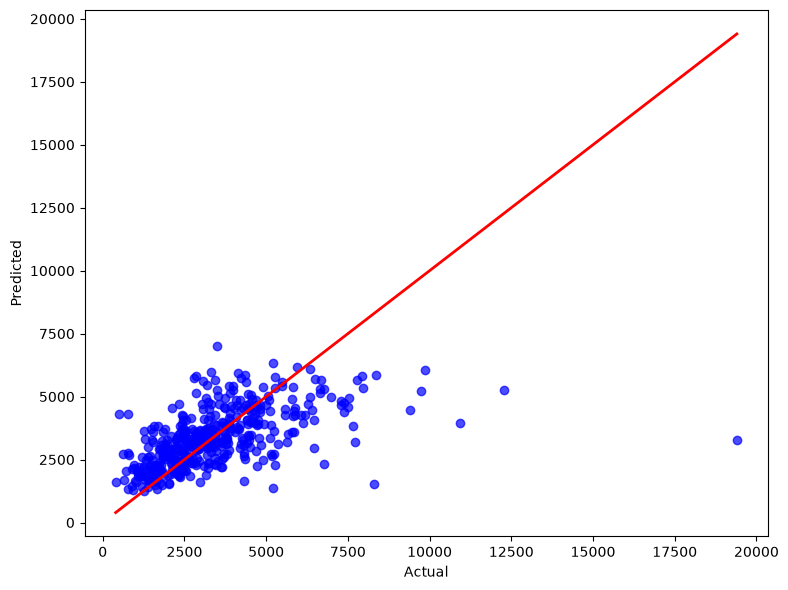

In [21]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred, alpha=0.7, color="blue")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", lw=2)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig10_rf_actual_vs_predicted.png", dpi=150)
plt.show()

### Figure 11: Feature importance (Random Forest)

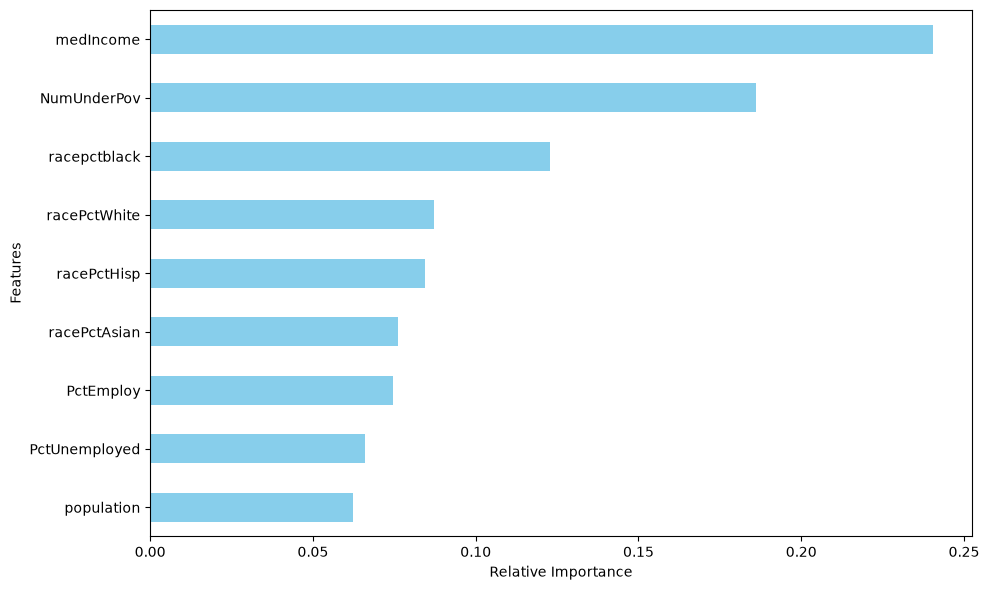

In [22]:
importances = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()

plt.figure(figsize=(10, 6))
importances.plot(kind="barh", color="skyblue")
plt.xlabel("Relative Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig11_rf_feature_importance.png", dpi=150)
plt.show()

### Residuals (Random Forest)

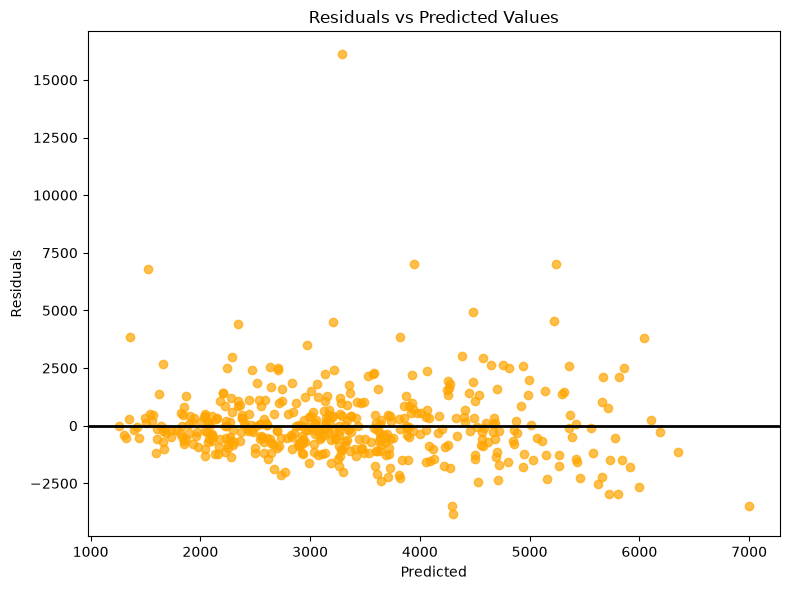

In [23]:
residuals = y_test - y_test_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_test_pred, residuals, alpha=0.7, color="orange")
plt.axhline(0, color="black", lw=2)
plt.title("Residuals vs Predicted Values")
plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.tight_layout()
plt.show()

## 6. K-Means clustering

Groups communities by their socioeconomic and demographic features (larceny rate is not used for
clustering), then compares the clusters' larceny rates.

### Figure 7: Elbow method

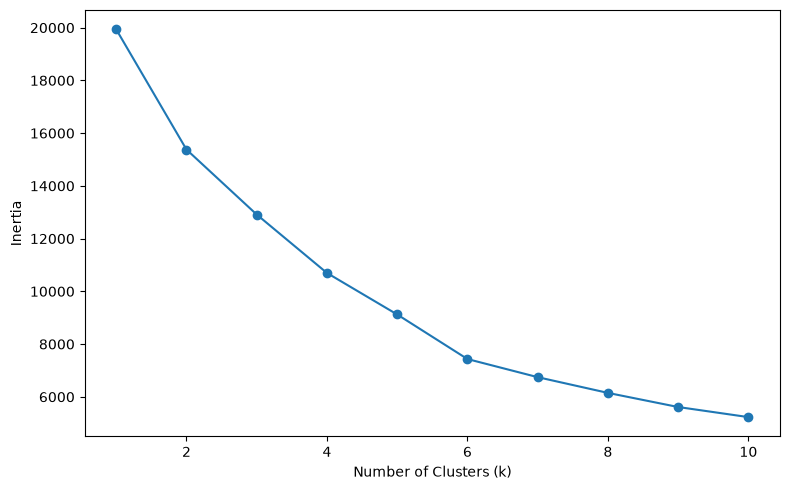

In [24]:
df_cluster = df_raw.copy()
X_scaled = StandardScaler().fit_transform(df_cluster[FEATURES])

k_range = range(1, 11)
inertia = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled).inertia_ for k in k_range]

plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, "-o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig07_kmeans_elbow.png", dpi=150)
plt.show()

The elbow is at k = 3.

### Figure 8: Visualization of clusters

Silhouette score: 0.33


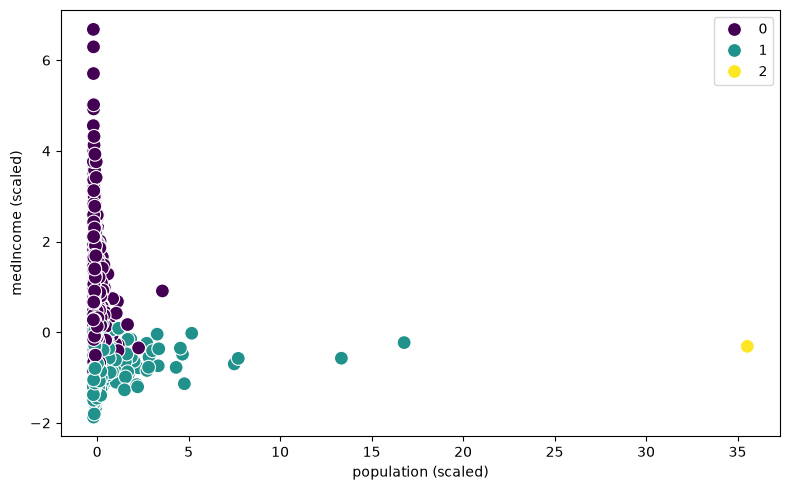

In [25]:
optimal_k = 3
clusters = KMeans(n_clusters=optimal_k, n_init=10, random_state=42).fit_predict(X_scaled)
df_cluster["Cluster"] = clusters

sil_score = silhouette_score(X_scaled, clusters)
print(f"Silhouette score: {sil_score:.2f}")

plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 1], hue=clusters, palette="viridis", s=100)
plt.xlabel(f"{FEATURES[0]} (scaled)")
plt.ylabel(f"{FEATURES[1]} (scaled)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig08_kmeans_clusters.png", dpi=150)
plt.show()

### Figure 9: Silhouette plot

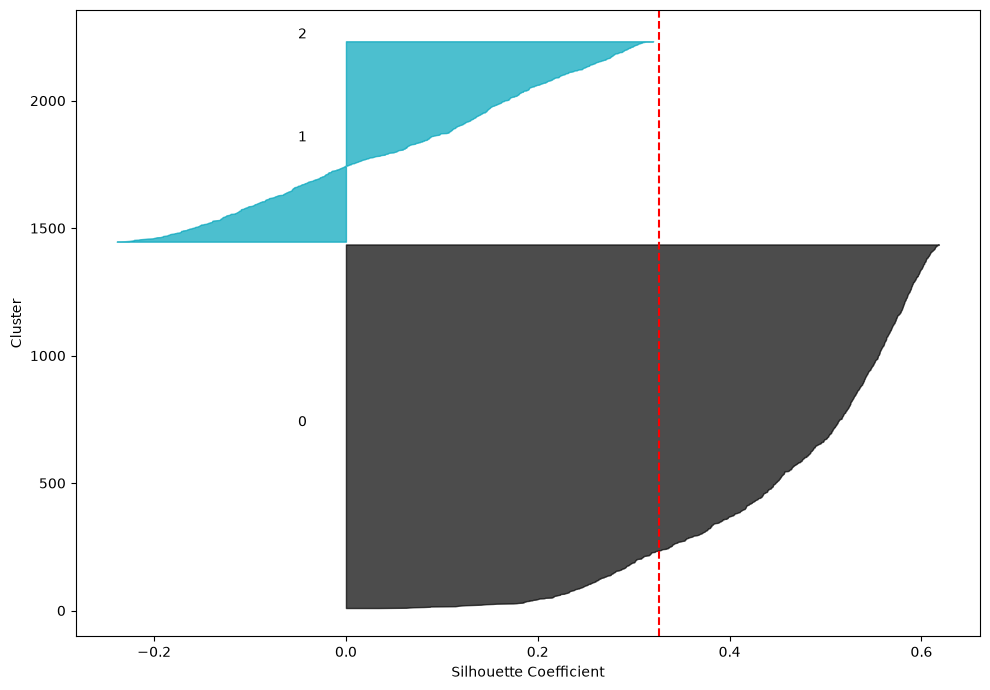

In [26]:
sil_values = silhouette_samples(X_scaled, clusters)

plt.figure(figsize=(10, 7))
y_lower = 10
for i in range(optimal_k):
    cluster_sil = np.sort(sil_values[clusters == i])
    y_upper = y_lower + len(cluster_sil)
    color = cm.nipy_spectral(i / optimal_k)
    plt.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_sil, facecolor=color, edgecolor=color, alpha=0.7)
    plt.text(-0.05, y_lower + 0.5 * len(cluster_sil), str(i))
    y_lower = y_upper + 10
plt.axvline(x=sil_score, color="red", linestyle="--")
plt.xlabel("Silhouette Coefficient")
plt.ylabel("Cluster")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig09_kmeans_silhouette.png", dpi=150)
plt.show()

### Cluster profiles and larceny rates

Cluster 2 contains only New York City. `population` and `NumUnderPov` are raw counts, and New York's
are so much larger than any other community's that it forms a cluster of its own. In practice the
clustering finds two groups of communities plus this one outlier.

In [27]:
df_cluster["larcPerPop"] = pd.to_numeric(df_cluster["larcPerPop"], errors="coerce")
df_cluster.groupby("Cluster")[FEATURES + ["larcPerPop"]].mean()

,population,medIncome,NumUnderPov,racepctblack,racePctWhite,racePctAsian,racePctHisp,PctUnemployed,PctEmploy,larcPerPop
Cluster,,,,,,,,,,
0,33074.706,39635.460,2461.645,3.422,91.649,2.927,4.315,4.555,65.840,2849.351
1,80223.844,23743.936,15141.015,20.032,70.114,2.198,14.520,8.743,55.106,4324.386
2,7322564.000,29823.000,1384994.000,28.710,52.260,7.000,24.360,8.980,56.120,3212.390


In [28]:
# Split larceny rates into three equal-sized groups and count how many communities in each cluster fall into each
with_rate = df_cluster.dropna(subset=["larcPerPop"]).copy()
with_rate["larcPerPop_bin"] = pd.qcut(with_rate["larcPerPop"], q=3, labels=["Low", "Medium", "High"])
pd.crosstab(with_rate["Cluster"], with_rate["larcPerPop_bin"])

larcPerPop_bin,Low,Medium,High
Cluster,,,
0,637,499,290
1,101,237,447
2,0,1,0
